### ボディ検査機 生産実績レポート
#### 1. 設備別 生産数
指定期間における各設備の生産数（OK数）を集計する。

In [1]:
import sqlite3

import matplotlib.pyplot as plt
import pandas as pd

# ================================================
#   Settings
# ================================================
plt.rcParams["font.family"] = "Yu Gothic"

DB_PATH = "body_inspection_machine.db"

START_DATE = "2026-09-01"
END_DATE = "2026-09-30"

In [2]:
sql = """
SELECT
    inspection_machine_no,
    SUM(ok_count) AS production_count
FROM inspection_data
WHERE record_date BETWEEN ? AND ?
GROUP BY inspection_machine_no
ORDER BY inspection_machine_no
"""

with sqlite3.connect(DB_PATH) as conn:
    df_production = pd.read_sql_query(
        sql,
        conn,
        params=(START_DATE, END_DATE),
    )

display(
    df_production.rename(
        columns={
            "inspection_machine_no": "設備番号",
            "production_count": "生産数",
        }
    ).style.format(
        {
            "生産数": "{:,}",
        }
    )
)

,設備番号,生産数
0,412,"294,941"
1,413,"270,490"
2,416,"254,573"
3,421,"235,501"
4,428,"305,445"


##### 設備別 生産数グラフ

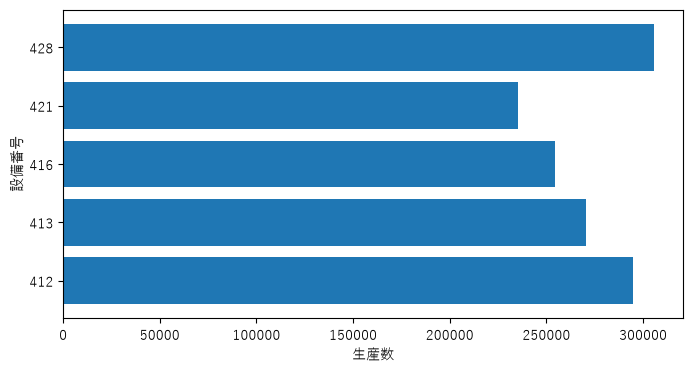

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))

ax.barh(
    df_production["inspection_machine_no"].astype(str),
    df_production["production_count"],
)

ax.set_xlabel("生産数")
ax.set_ylabel("設備番号")

plt.show()